# Caribu: light in plant canopies, in metafspm

Caribu (`openalea.caribu`) computes the light that each triangle of a canopy receives and absorbs. This package is
its port to Python (numpy, numba), without its C++ executables or files, and a metafspm component built on it:
- **direct light**: each source projected on a z-buffer, the canopy infinite when a pattern repeats it;
- **radiosity**: every order of scattering between the triangles of a closed scene;
- **nested radiosity**: in an infinite canopy, radiosity between the triangles within a sphere, and a turbid medium
  of layers beyond it (mcsail: SAIL with several layers); with a null sphere, pure SAIL;
- **light sources**: turtle skies, sector skies (standard or uniform overcast), the sun's position, the diffuse
  fraction of global radiation;
- **`CaribuLight`**: a metafspm `FunctionalComponent`, which lights the elements of one or several plant
  populations from their triangles.

The previous package is kept in `openalea.caribu.legacy`. It drives libcaribu's executables, and the port is
compared with it in the tests. By default (`precision="legacy"`) every output equals the legacy's, digit for digit.
`corrections="recommended"` corrects its behaviours, each tested by the physics it restores. The component uses the
corrections by default.

The steps:
0. reading the code: metafspm's component formalism, on `CaribuLight`;
1. the light models on a canopy's triangles;
2. the light sources;
3. the infinite canopy and the corrections;
4. lighting a canopy again: the `Canopy`;
5. `CaribuLight` in a metafspm scene, on a stand grown by Adel's port;
6. the comparison with the legacy, and the speed.

Lengths are in m, irradiances in the light sources' unit (here relative: a sky of unit energy).

In [1]:
import inspect
import time

import matplotlib.pyplot as plt
import numpy as np

from openalea.caribu import corrections, direct, formats, lights, nested, radiosity
from openalea.caribu.canopy import Canopy
from openalea.caribu.component import CaribuLight, CaribuLightModel
from openalea.caribu.labels import encode_labels
from openalea.caribu.legacy.data_samples import data_path

## 0. Reading the code: metafspm's component formalism

`CaribuLight` is a metafspm `FunctionalComponent`. All the ported models are written in the same form; this section
presents it on `CaribuLight`, so that its code (`openalea.caribu.component`) can be read. For more, metafspm's
tutorial `examples/soil_plant_atmosphere/tutorial_fspm2026_general_usage.ipynb` (in the metafspm repository) builds
components step by step; its user guide `docs/user.md` describes each part.

- **A component is a dataclass.** Its fields declare its variables:
  - `input_variable`: written by another model (`by`), read here;
  - `state_variable`: computed by this component;
  - `parameter`: a constant, which may differ between plants.

  Each declaration documents its variable (`unit`, `description`) and places it at a **scale** of the plant graph:
  `CaribuLight`'s are at the elements' scale, `SubOrgan`.
- **Its processes are steps:** methods decorated by their place in the schedule (`@rate`, `@state`, ...). A step's
  arguments are variables, named as declared. Each comes as a whole array, one value per element, for every plant
  at once. A step returns its output, named after the method, or several outputs as a dict `{name: values}`.
- **The values live in the DataStructure**, one array per variable: `ds.get(name)`, `ds.set(name, values)`. The plant
  graph (an MTG, metafspm's MPG) holds the topology and the labels, read through `ds.structure`.
- **An environment model lights the plants.** A metafspm `Scene` builds each population of plants and gives the
  environment models their DataStructures: `CaribuLightModel(populations, scene_xrange, scene_yrange, time_step)`
  builds `CaribuLight` on the population's DataStructure, or on a `UnionDataStructure` of several populations.
- **The geometry comes from the structural component.** A `StructuralComponent` (Adel's `ShootArchitecture`, a root
  model's segments) registers itself on its DataStructure, and `ds.triangles()` returns the elements' triangles with
  each one's node index. `CaribuLight` reads them at each lighting, and gives its results back per element.

`CaribuLight.declarations()` lists what the component declares:

In [2]:
declarations = CaribuLight.declarations()
print(declarations["kind"].value_counts().to_string())
declarations.loc[declarations["kind"] != "parameter", ["name", "kind", "scale", "unit", "description"]]

kind
parameter         21
state_variable     5
input              2


,name,kind,scale,unit,description
0,PAR_reflectance,input,SubOrgan,adim,The element's reflectance in the PAR (NaN: its...
1,PAR_transmittance,input,SubOrgan,adim,The element's transmittance in the PAR (NaN: o...
2,Erel,state_variable,SubOrgan,adim,"The PAR the element absorbs per unit area, rel..."
3,PARa,state_variable,SubOrgan,µmol m-2 s-1,The PAR the element absorbs per unit area
4,Erel_incident,state_variable,SubOrgan,adim,The PAR reaching the element per unit area (it...
5,PAR_incident,state_variable,SubOrgan,µmol m-2 s-1,The PAR reaching the element per unit area
6,lit_area,state_variable,SubOrgan,m2,The element's area in the light model (its tri...


Its parameters choose the light model, the sky, the sun and the corrections. Their defaults reproduce
Wheat-BRIDGES' use of Caribu: direct light in an infinite canopy under a standard overcast sky of 4 × 5 sectors,
leaves of (ρ, τ) = (0.10, 0.05), stems of ρ = 0.10, lit every 4 hours.

In [3]:
declarations.loc[declarations["kind"] == "parameter", ["name", "default", "unit", "description"]]

,name,default,unit,description
7,optical_properties,"((LeafElement, (0.1, 0.05)), (StemElement, (0....",adim,"(label, material) pairs for the elements witho..."
8,mode,direct,,"'direct', 'nested' (scattering in the infinite..."
9,infinite,True,,The pattern repeated (direct light); nested is...
10,sky,sectors,,'sectors' (azimuth_sectors x zenith_sectors) o...
11,sky_type,soc,,'soc' standard overcast or 'uoc' uniform
12,azimuth_sectors,4,,The sector sky's azimuths
13,zenith_sectors,5,,The sector sky's zeniths
14,sun,False,,The sun with the diffuse sky (its share 1 - th...
15,latitude,48.85,°,The scene's latitude
16,orientation,0.0,°,"The angle, clockwise, from the scene's X+ to N..."


Its schedule has one step. `_light` reads the elements' optics and the parameters as arguments, and the forcing
`PARi` (the incident PAR, from the scene's forcings) through `self.forcing`. When the canopy is due to be lit, it
calls `lit`, which runs Caribu on `ds.triangles()`.

In [4]:
for stages, steps in CaribuLight.schedule():
    print(f"{', '.join(stages):>10}  {', '.join(steps)}")
print(inspect.getsource(CaribuLight._light))

      rate  _light
    @rate(include_inactive=True)
    def _light(self, PAR_reflectance, PAR_transmittance, azimuth_sectors, zenith_sectors, latitude, orientation,
               start_day_of_year, start_hour, global_per_PARi, lighting_interval, sphere_diameter, layers,
               soil_reflectance, screen_size) -> dict:
        """Erel when the canopy is due to be lit, PARa = Erel · PARi at every step."""
        PARi = self.forcing("PARi")
        time = self.forcing_time()
        last = self.__dict__.get("_lit_at")
        relative = self.__dict__.get("_relative")
        n_elements = PAR_reflectance.size
        first = lambda values: float(np.asarray(values).flat[0])
        if relative is None or relative[0].size != n_elements or time - last >= first(lighting_interval) - 1e-9:
            day = first(start_day_of_year) + (first(start_hour) * 3600. + time) // 86400.
            hour = (first(start_hour) + time / 3600.) % 24.
            sources = self.sources(PARi, day, hour,

## 1. The light models on a canopy's triangles

Under the component, the models work on arrays:
- **vertices** `(n, 3, 3)`: the triangles;
- **labels** `(n,)`: each triangle's optical species, and whether it is a leaf (two faces, translucent) or opaque (a
  stem, one face). `encode_labels(species, leaf=...)` writes them;
- **optics**: `(soil reflectance, {species: (ρ stem, ρ upper, τ upper, ρ lower, τ lower)})`;
- **lights**: `[(E, (vx, vy, vz))]`, E the irradiance on a horizontal plane and (vx, vy, vz) the beam's direction;
- a **pattern** `(xmin, ymin, xmax, ymax)` for an infinite canopy, repeated in x and y.

The canopy here is the legacy's 100-plant Adel scene (34,647 triangles, in m), its pattern the scene's extent,
under the 46-direction turtle sky:

In [5]:
vertices, labels = formats.read_can_arrays(data_path("f331s1_100plantes.can"))
flat = vertices.reshape(-1, 3)
pattern = (float(flat[:, 0].min()), float(flat[:, 1].min()), float(flat[:, 0].max()), float(flat[:, 1].max()))
ground = (pattern[2] - pattern[0]) * (pattern[3] - pattern[1])
height = float(flat[:, 2].max())
labels = encode_labels(1, leaf=1, plant=(labels // 10 ** 6) % 10 ** 5)   # one species of leaves
optics = (0.15, {1: (0.10, 0.10, 0.05, 0.10, 0.05)})
sky = lights.turtle_lights("46", "soc", energy=1.)
print(f"{len(vertices)} triangles, pattern {np.round(pattern, 3)}, {len(sky)} sources")

34644 triangles, pattern [-2.936 -3.499  0.526  0.505], 46 sources


The models, with the corrections (and `precision="full"`, the values as computed):
- `direct.run`: the first order only;
- `nested.run(..., diameter=0)`: pure SAIL, the first order plus the turbid medium's scattered light;
- `nested.run(..., diameter=D)`: nested radiosity, radiosity within a sphere of diameter D.

Each returns, per triangle, its `area`, the irradiance `Ei` (both faces), the absorbed `Eabs`, both per unit area:

In [6]:
recommended = corrections.resolve("recommended")


def absorbed(result):
    """The canopy's absorbed light per m² of ground."""
    return float(np.nansum(np.asarray(result["Eabs"], dtype=float) * result["area"])) / ground


direct.run(vertices[:300], labels[:300], sky[:2], optics, pattern=pattern)     # numba compiles at the first calls
nested.run(vertices[:300], labels[:300], sky[:2], optics, pattern, 3, height, 0.5)
models = {"direct": lambda: direct.run(vertices, labels, sky, optics, pattern=pattern, corrections=recommended),
          "pure SAIL": lambda: nested.run(vertices, labels, sky, optics, pattern, 10, height, 0., precision="full",
                                          corrections=recommended),
          "nested D = 0.25 m": lambda: nested.run(vertices, labels, sky, optics, pattern, 10, height, 0.25,
                                                  precision="full", corrections=recommended),
          "nested D = 0.5 m": lambda: nested.run(vertices, labels, sky, optics, pattern, 10, height, 0.5,
                                                 precision="full", corrections=recommended)}
results = {}
for name, run in models.items():
    started = time.perf_counter()
    results[name] = run()
    print(f"{name:>18}: absorbed {absorbed(results[name]):.3f} per m² of ground, in {time.perf_counter() - started:.2f} s")

            direct: absorbed 0.610 per m² of ground, in 0.61 s


         pure SAIL: absorbed 0.704 per m² of ground, in 0.71 s


 nested D = 0.25 m: absorbed 0.697 per m² of ground, in 1.34 s


  nested D = 0.5 m: absorbed 0.697 per m² of ground, in 1.75 s


Scattering adds light: the canopy absorbs more with the turbid medium's scattered light than with direct light only.
Down the canopy, the light each leaf absorbs falls as the leaf area above it grows:

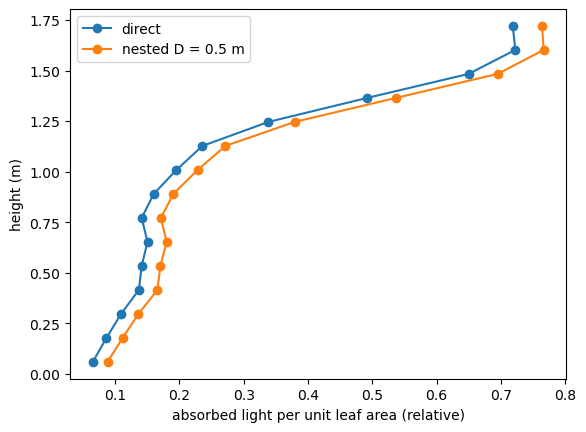

In [7]:
centres = vertices.mean(axis=1)
bins = np.linspace(0, height, 16)
layer = np.digitize(centres[:, 2], bins)
for name in ("direct", "nested D = 0.5 m"):
    result = results[name]
    eabs, area = np.nan_to_num(np.asarray(result["Eabs"], dtype=float)), np.asarray(result["area"])
    mean = [np.sum((eabs * area)[layer == k]) / max(np.sum(area[layer == k]), 1e-12) for k in range(1, len(bins))]
    plt.plot(mean, bins[1:] - (bins[1] - bins[0]) / 2, "o-", label=name)
plt.xlabel("absorbed light per unit leaf area (relative)")
plt.ylabel("height (m)")
plt.legend();

Radiosity in a closed scene (`radiosity.run`) computes every exchange between the triangles: the full scene's
1.26 M pairs take about a minute. Here the first 3,000 triangles:

In [8]:
started = time.perf_counter()
closed = radiosity.run(vertices[:3000], labels[:3000], sky, optics, corrections=recommended)
first_order = direct.run(vertices[:3000], labels[:3000], sky, optics, corrections=recommended)
print(f"radiosity on 3,000 triangles in {time.perf_counter() - started:.1f} s ({closed['steps']} solver steps); "
      f"scattering adds {np.nansum(closed['Eabs'] * closed['area']) / np.nansum(first_order['Eabs'] * first_order['area']) - 1:.1%} "
      f"to the absorbed light")

radiosity on 3,000 triangles in 0.7 s (5 solver steps); scattering adds 7.8% to the absorbed light


## 2. The light sources

`lights` builds the sources:
- `turtle_lights("46" or "16", "soc" or "uoc", energy)`: the turtle's directions;
- `Sky(azimuths, zeniths).diffuse(energy, "soc")`: sectors of a standard (soc) or uniform (uoc) overcast sky,
  `.place_sun(sun)` or `.add_sun(sun)`, `.lights()`;
- `sun_light(energy, day_of_year, hour, latitude)`, `Sun().place(...)`: the sun;
- `diffuse_fraction(global_radiation, day_of_year, hour, latitude)`: Spitters' diffuse fraction;
- `hourly_global_radiation(daily, hour, day_of_year, latitude)`: the hours of a day's global radiation.

With `corrections="recommended"`, the azimuths are counted from North, clockwise, X+ at `orientation` degrees from
North. A clear May day at Paris (28 MJ m-2 of global radiation):

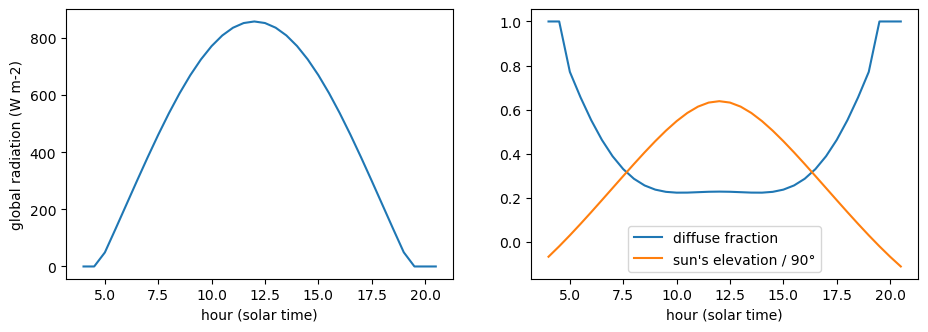

In [9]:
hours = np.arange(4., 21., 0.5)
global_radiation = [max(lights.hourly_global_radiation(28e6, hour, 126, 48.85), 0.) for hour in hours]
fraction = [lights.diffuse_fraction(value, 126, hour, 48.85) if value > 0 else 1. for value, hour in zip(global_radiation, hours)]
elevation = [90 - np.degrees(lights.Sun(corrections="recommended").place(126, hour, np.radians(48.85)).zenith) for hour in hours]
figure, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(hours, global_radiation)
axes[0].set_ylabel("global radiation (W m-2)")
axes[1].plot(hours, fraction, label="diffuse fraction")
axes[1].plot(hours, np.array(elevation) / 90, label="sun's elevation / 90°")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("hour (solar time)")

## 3. The infinite canopy and the corrections

In an infinite canopy the pattern repeats the scene. A triangle across the pattern's border belongs to both sides:
its part beyond the border is the neighbouring pattern's. canestrad copies such a triangle only towards +x and +y,
and its screen does not always reach the part beyond. A lone leaf across the border then receives less than the
light on the ground:

In [10]:
def square(x, y, side, z=0.5):
    a, b, c, d = (x, y, z), (x + side, y, z), (x + side, y + side, z), (x, y + side, z)
    return np.array([[a, b, c], [a, c, d]])


leaf_label, unit_pattern = encode_labels(1, leaf=1), (0., 0., 1., 1.)
print("leaf corner   legacy   corrected   (Ei, the incident light per unit area; the ground receives 1)")
for x, y in ((0.3, 0.3), (0.8, 0.4), (0.8, 0.8), (-0.1, -0.1)):
    row = []
    for chosen in ((), recommended):
        result = direct.run(square(x, y, 0.3), leaf_label, sky, optics, pattern=unit_pattern, corrections=chosen)
        row.append(np.sum(result["Ei"] * result["area"]) / np.sum(result["area"]))
    print(f"({x:4.1f}, {y:4.1f})   {row[0]:6.3f}   {row[1]:9.3f}")

leaf corner   legacy   corrected   (Ei, the incident light per unit area; the ground receives 1)


( 0.3,  0.3)    0.999       1.000


( 0.8,  0.4)    0.927       1.000


( 0.8,  0.8)    0.685       1.001


(-0.1, -0.1)    0.780       1.000


The corrections (`openalea.caribu.corrections`), each tested in `test/test_corrections.py`:

In [11]:
for name, description in corrections.NAMES.items():
    print(f"{name:>22}  {description}")

         border_copies  a triangle across the pattern's borders copied on each side it crosses, corners included
                tiling  the neighbouring patterns' images placed by the lattice's exact vectors, each translate rounded on its own, its depth offset exact
         sensor_copies  sensors copied across the borders as triangles, each copy's pixels counted once
            pixel_area  a pixel's area the pitch's, du dv / (T - 1)^2
          upward_beams  a source whose beam goes up or along the ground lights nothing
             periodise  the periodised scene in float32 without its text rounding, lifted to exactly z >= 0
         triangle_area  a triangle's area 0.5 |AB x AC|
           voxel_floor  the receiver's voxel floor((G - O) / side)
           face_counts  an emitter's two faces counted apart
        projected_face  each pixel's emitter face the one of the copy projected there
 profile_interpolation  the far field's levels interpolated with weights (1 - f, f)
        p

Two of them make the results independent of the scene's unit. canestrad finds a receiver's neighbours from its
voxel, `int(trunc(G − O) / side)`: in metres, with a sphere below 1 m, most near neighbours are searched around the
wrong voxel and left to the far field. And it tiles the neighbouring patterns by steps rounded to pixels, repeated:
the k-th neighbour lies up to k pixels off. The same canopy in m and in cm:

In [12]:
random = np.random.default_rng(3)
leaf_centres = np.c_[random.uniform(0, 0.4, (300, 2)), random.uniform(0.05, 0.6, 300)]
small = np.array([[c, c + random.normal(0, 0.03, 3), c + random.normal(0, 0.03, 3)] for c in leaf_centres])
sky16 = lights.turtle_lights("16", "soc", 1.)
for name, chosen in (("legacy", frozenset()), ("corrected", recommended)):
    runs = [nested.run(small * scale, leaf_label, sky16, optics, (0, 0, 0.4 * scale, 0.4 * scale), 5, 0.65 * scale,
                       0.1 * scale, precision="full", corrections=chosen, size=512) for scale in (1., 100.)]
    pairs = [len(run["counts"][1]) for run in runs]
    difference = np.abs(np.asarray(runs[0]["Eabs"], float) - np.asarray(runs[1]["Eabs"], float))
    print(f"{name:>9}: near-field pairs in m {pairs[0]}, in cm {pairs[1]}; Eabs m vs cm, mean |difference| {difference.mean():.1e}")

   legacy: near-field pairs in m 59, in cm 435; Eabs m vs cm, mean |difference| 3.6e-03
corrected: near-field pairs in m 610, in cm 609; Eabs m vs cm, mean |difference| 1.3e-04


## 4. Lighting a canopy again: the `Canopy`

A `Canopy` keeps what depends only on the geometry: the scene as canestrad reads it, each direction's lit areas,
the near field's form factors. A second band, other optics or a new hour then cost little:

In [13]:
canopy = Canopy(vertices, labels, pattern=pattern, corrections="recommended")
for name, band_optics in (("PAR", optics), ("NIR", (0.2, {1: (0.4, 0.45, 0.45, 0.45, 0.45)}))):
    started = time.perf_counter()
    result = canopy.direct(sky, band_optics)
    print(f"{name}: absorbed {absorbed(result):.3f}, in {time.perf_counter() - started:.2f} s")

PAR: absorbed 0.610, in 0.52 s
NIR: absorbed 0.072, in 0.12 s


`example/day_course.py` lights the canopy hour by hour, the sky's directions projected once.

## 5. `CaribuLight` in a metafspm scene

A stand of 20 wheat plants grown by Adel's port (`openalea.adel`, its `ShootArchitecture` drawing the elements),
lit by `CaribuLightModel`. Each scene step is an hour and 10 °Cd. The scene's forcing `PARi` is the incident PAR of
clear May days (µmol m-2 s-1). `CaribuLight` lights the canopy every 4 hours, under the sky and the sun, the diffuse
fraction Spitters' (from PARi). In between, each element's PARa follows PARi with its last Erel:

96 hours in 20.1 s, 22065 triangles at the end


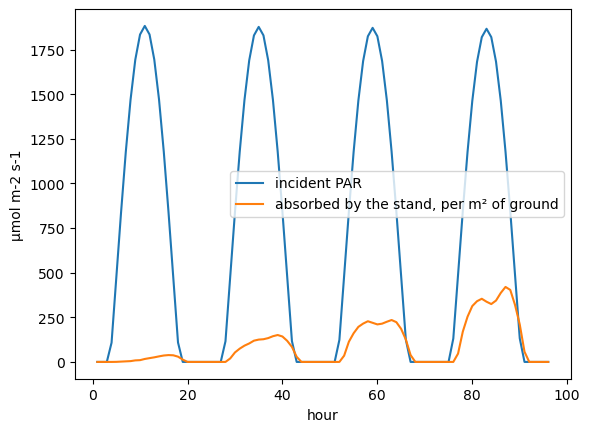

In [14]:
import sys
sys.path.insert(0, "..")                                   # example/canopy_light.py
from canopy_light import XRANGE, YRANGE, incident_PAR, stand_scene

scene = stand_scene()
ds = scene.populations[0].data_structure
light = scene.environment[0].light
hours, incident, stand_absorbed = [], [], []
started = time.perf_counter()
for step in range(96):
    scene.run()
    hours.append(scene.time / 3600.)
    incident.append(light.forcing("PARi"))
    stand_absorbed.append(float(np.sum(np.asarray(ds.get("PARa")) * np.asarray(ds.get("lit_area")))) / (XRANGE * YRANGE))
print(f"96 hours in {time.perf_counter() - started:.1f} s, {len(ds.triangles())} triangles at the end")
plt.plot(hours, incident, label="incident PAR")
plt.plot(hours, stand_absorbed, label="absorbed by the stand, per m² of ground")
plt.xlabel("hour")
plt.ylabel("µmol m-2 s-1")
plt.legend();

Each element's `Erel` (absorbed per unit area, relative to the incident PAR), drawn with metafspm's `display`:

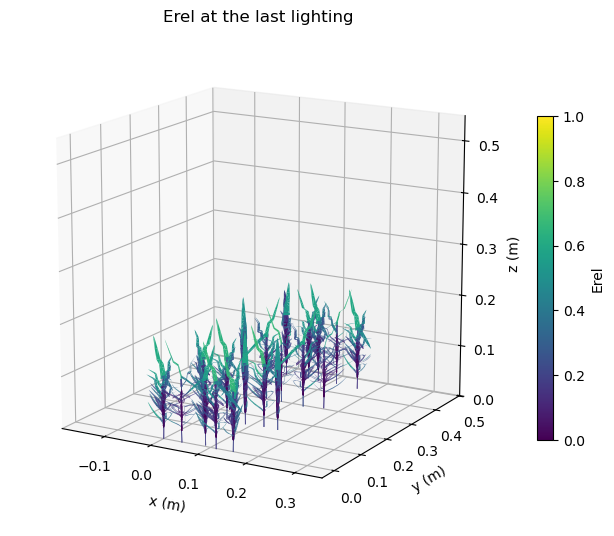

In [15]:
from openalea.metafspm.display import draw, value_colors

figure = plt.figure(figsize=(8, 7))
axes = figure.add_subplot(projection="3d")
draw(axes, ds.triangles(), colors=value_colors(np.asarray(ds.get("Erel")), limits=(0., 1.)), shade=False)
figure.colorbar(plt.cm.ScalarMappable(cmap="viridis"), ax=axes, shrink=0.6, label="Erel")
axes.set_title("Erel at the last lighting");

Several populations (an intercrop, two genotypes) share the light: `CaribuLightModel` then runs on a
`UnionDataStructure` of their DataStructures, and the scene's translator gives each population its outputs, e.g.
`translator.link("WheatPhotosynthesis", "PARa", "CaribuLight", {"PARa": 1.})` (`test/test_component.py`).

A coupled model can give each element its optics, through the inputs `PAR_reflectance` and `PAR_transmittance`; a
NaN transmittance makes it opaque. Elements without optics of their own take their MTG label's in
`optical_properties`.

## 6. The comparison with the legacy, and the speed

With `precision="legacy"` and no corrections, every output equals the legacy's to its printed digits:
canestrad's, s2v's and mcsail's files, the API's dicts (`test/comparison`). The legacy's own tests run on the port.
`CaribuLight` with `precision="legacy"` and `corrections=()` reproduces Wheat-BRIDGES' Erel exactly
(`test/test_component_adel.py`).

The time of each model on the Adel scene (34,647 triangles, 46 sources; a laptop, the legacy when libcaribu is
installed):

In [16]:
from openalea.caribu.comparison import legacy_run, port_run

materials = {1: (0.10, 0.05)}
legacy_optics = port_run.optics(materials, 0.15)
cases = (("direct", lambda: direct.run(vertices, labels, sky, legacy_optics, pattern=pattern),
          lambda: legacy_run.direct(vertices, labels, sky, materials, 0.15, pattern=pattern)),
         ("pure SAIL", lambda: nested.run(vertices, labels, sky, legacy_optics, pattern, 10, height, 0),
          lambda: legacy_run.layered(vertices, labels, sky, materials, pattern, 10, height, 0.15)),
         ("nested D = 0.5 m", lambda: nested.run(vertices, labels, sky, legacy_optics, pattern, 10, height, 0.5),
          lambda: legacy_run.layered(vertices, labels, sky, materials, pattern, 10, height, 0.15, diameter=0.5)))
for name, port, legacy in cases:
    started = time.perf_counter()
    port()
    port_time = time.perf_counter() - started
    legacy_time = None
    if legacy_run.available():
        started = time.perf_counter()
        legacy()
        legacy_time = time.perf_counter() - started
    print(f"{name:>17}: port {port_time:5.2f} s" + (f", legacy {legacy_time:5.2f} s" if legacy_time else ""))

           direct: port  0.59 s, legacy  3.19 s


        pure SAIL: port  0.72 s, legacy  3.76 s


 nested D = 0.5 m: port  2.38 s, legacy 12.56 s


The full radiosity of the whole scene takes about 62 s against canestrad's 307 s; with `device="cuda"`, the near
field runs on a GPU (numba.cuda, tested under its simulator).